# v10 interpretability, part 3a (GPU 0): H3 fixed + H7 steering
- **H3 fixed:** what decoder neurons write, now counting only tokens the model can actually output in Hindi (the script filter).
- **H7 steering:** take 25% of each decoder layer (self / look-alike task / random task, 3 draws). Push those neurons along their own 'confident minus unsure' direction (measured on even sentences) by -2x ... +2x. Measure on odd sentences: does the model's uncertainty move with the push? Does loss / chrF (200 devtest sentences) hold up?
Needs part 1 (`interp_v10.ipynb`). Results: `analysis/v10/interp2/`.

In [1]:
import os, sys, glob, json, time, subprocess
os.environ["HF_HUB_DISABLE_XET"] = "1"
GPU = "0"
REPO = "/workspace/shreshth"; os.chdir(REPO); sys.path.insert(0, REPO)
from IPython.display import Image, display
from huggingface_hub import HfApi, hf_hub_download
for attempt in range(5):
    try:
        api = HfApi(); HF_REPO = api.whoami()["name"] + "/cml-lang-self-checkpoints"; FILES = api.list_repo_files(HF_REPO); break
    except Exception as e:
        print("HF retry", attempt, type(e).__name__); time.sleep(10)

def get(run, phases):
    for ph in phases:
        if glob.glob(f"runs/{run}/ckpt/p{ph:03d}_*.pt"):
            continue
        name = [f for f in FILES if f.startswith(f"{run}/ckpt/p{ph:03d}_")]
        if name:
            hf_hub_download(HF_REPO, name[0], local_dir="runs")
        else:
            print("missing (not here, not on HF):", run, ph)

def last_phase(run):
    phs = [int(os.path.basename(f)[1:4]) for f in FILES if f.startswith(f"{run}/ckpt/p")]
    phs += [int(os.path.basename(f)[1:4]) for f in glob.glob(f"runs/{run}/ckpt/p*.pt")]
    return max(phs)


def run(*cmd):
    env = {**os.environ, "CML_LANGSET": "distant"}
    p = subprocess.Popen([sys.executable, "-u", "interp2_v10.py", "--gpu", GPU, *cmd], stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, env=env)
    for line in p.stdout:
        print(line, end="")
    p.wait(); print("exit code", p.returncode)

MODELS = [("hindi45", "v4b_only_hi_s0", 45), ("cont40", "v4b_continual_s0", 40), ("cont10", "v4b_continual_s0", 10)]
for _, r, ph in MODELS:
    get(r, [ph])
need = ["data/en-hi/train.jsonl", "tokenizer_v4/spm.model"] + [f"data/flores/dev.{l}.jsonl" for l in ["en", "hi", "zh", "ar"]]
miss = [f for f in need if not os.path.exists(f)]
print("all there" if not miss else f"MISSING: {miss}")

/venv/main/lib/python3.12/site-packages/huggingface_hub/constants.py:302: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(


all there


In [2]:
import glob as _g
for f in ["h3_*.csv", "h7_*.csv"]:
    for x in _g.glob("analysis/v10/interp2/" + f): os.remove(x)
for n, r, ph in MODELS:
    run("--model", f"{n}={r}:{ph}", "--parts", "h3,h7")
run("--model", "random=random", "--parts", "h3")

30 most common Hindi words: के है में और की से को का हैं पर कि एक लिए तो नहीं भी जो हो ने यह किया ही कर इस वह करने न था या अपने


recorded in 1s


  H3 dec0


  H3 dec1


  H3 dec2


  H3 dec3


... (183 outputs left out)

  H3 dec1


  H3 dec2


  H3 dec3
done


exit code 0


=== H2: when does the self fire? average z-activity, self minus task neurons (positive = self fires MORE on this kind) ===

-- by kind (rows: model, side; columns: category)
category      English word start  English word-piece  Hindi word start  Hindi word-piece  Latin  common word  number  other  punct
model   side                                                                                                                      
cont10  dec                  NaN                 NaN             0.004             0.012  0.025       -0.022  -0.036  0.116  0.012
        enc               -0.009              -0.030               NaN               NaN    NaN        0.034   0.078 -0.059  0.049
cont40  dec                  NaN                 NaN             0.004             0.014  0.022       -0.022  -0.053  0.112  0.013
        enc               -0.005              -0.007               NaN               NaN    NaN        0.012   0.065 -0.017  0.007
hindi45 dec                  NaN        


=== H3: what do decoder neurons write? share of each neuron's top-20 promoted tokens by kind (self vs task) ===
kind                 Hindi word start  Hindi word-piece  Latin  common word  number  other  punct
model   layer group                                                                              
cont10  dec0  self              0.497             0.415    0.0        0.031   0.003  0.001  0.054
              task              0.476             0.442    0.0        0.027   0.002  0.000  0.053
        dec1  self              0.531             0.338    0.0        0.061   0.003  0.002  0.065
              task              0.477             0.409    0.0        0.046   0.002  0.001  0.065
        dec2  self              0.486             0.373    0.0        0.067   0.005  0.002  0.067
              task              0.457             0.412    0.0        0.061   0.002  0.003  0.065
        dec3  self              0.500             0.393    0.0        0.045   0.006  0.003  0.052
     


=== H7: push 25% of each decoder layer along the 'confident minus unsure' direction (x = how far, 1 = the natural gap) ===
-- change in uncertainty (entropy; negative = MORE confident), average of 3 draws
alpha               -2.0   -1.0   -0.5    0.5    1.0    2.0
model   group                                              
cont10  lookalike  0.065  0.031  0.015 -0.014 -0.028 -0.054
        random     0.070  0.034  0.017 -0.016 -0.031 -0.060
        self      -0.250 -0.185 -0.109  0.148  0.341  0.876
cont40  lookalike -0.005 -0.004 -0.002  0.003  0.006  0.014
        random     0.000 -0.001 -0.001  0.001  0.002  0.007
        self      -0.295 -0.221 -0.133  0.187  0.436  1.141
hindi45 lookalike  0.030  0.013  0.006 -0.004 -0.008 -0.010
        random     0.008  0.002  0.000  0.001  0.002  0.008
        self      -0.369 -0.281 -0.167  0.228  0.525  1.350
-- change in loss
Empty DataFrame
Columns: []
Index: []
-- change in chrF (200 devtest sentences, pushes of -2x and +2x)
alpha        


=== H5: how many dimensions does the activity really use? (participation ratio; per 100 neurons so self and task compare fairly) ===
layer           dec0   dec1   dec2   dec3   enc0   enc1   enc2   enc3
model   group                                                        
cont10  self   35.13  35.20  27.50  11.43  44.53  50.46  47.10  37.70
        task   65.64  63.55  60.98  53.07  64.28  67.24  70.13  70.72
cont40  self   36.06  41.35  33.70  13.84  51.85  61.08  57.32  47.64
        task   66.36  57.82  61.92  50.60  65.28  72.02  72.50  73.32
hindi45 self   41.95  44.48  32.51  11.30  44.12  48.08  46.65  34.13
        task   59.48  60.62  50.49  38.70  61.23  64.01  65.24  61.72
random  self    6.50   5.13   4.73   4.43   6.84   7.08   7.02   6.98
        task   75.66  88.46  91.57  94.06  96.31  92.30  92.69  94.38

-- share of variance in the top 1 / top 3 directions
layer           dec0   dec1   dec2   dec3   enc0   enc1   enc2   enc3
model   group                             

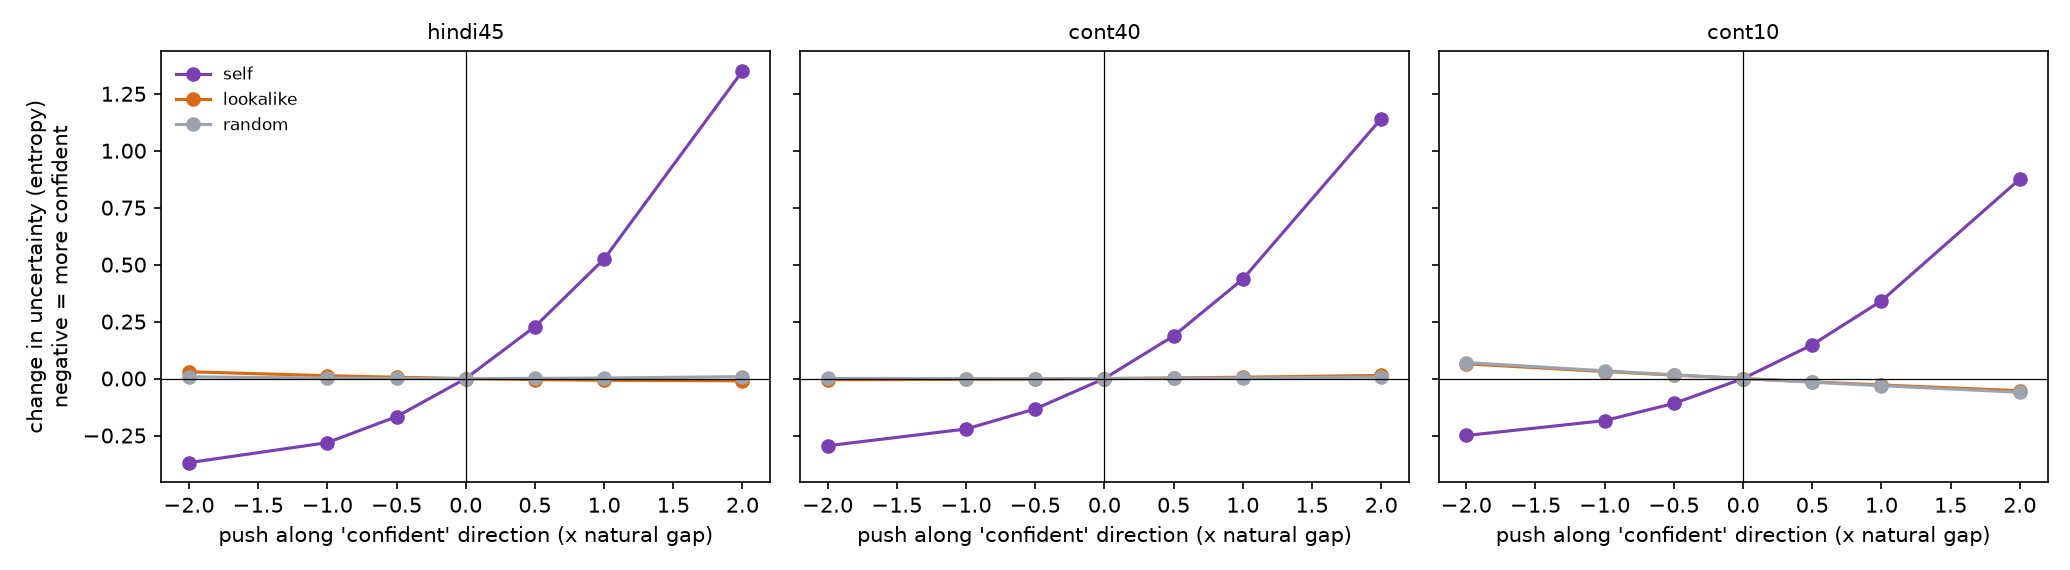

In [3]:
subprocess.run([sys.executable, "interp2_v10.py", "--summarize"])
for f in ["h7_steer.png"]:
    if os.path.exists(f"analysis/v10/interp2/{f}"): display(Image(f"analysis/v10/interp2/{f}"))